In [1]:
from time import sleep

import pyscan as ps
from pyscan.drivers.thorlabs.thorlabspm16_120 import ThorlabsPM16_120

In [2]:
devices = ps.ItemAttribute()


devices.x1 = ps.Agilent33500('USB0::0x0957::0x5707::MY53804557::INSTR', 1)
devices.y1 = ps.Agilent33500('USB0::0x0957::0x5707::MY53804557::INSTR', 2)

devices.x2 = ps.Agilent33500('USB0::0x0957::0x2307::SG50000115::INSTR', 1)
devices.y2 = ps.Agilent33500('USB0::0x0957::0x2307::SG50000115::INSTR', 2)

devices.pm16_120 = ThorlabsPM16_120()

devices.laser = ps.PulseLaser('COM7')

COM7


In [3]:
def measure_power(expt):
    d = ps.ItemAttribute()
    d.power = devices.pm16_120.power
    return d

In [16]:
# devices.x1.voltage = 0.02
# devices.y1.voltage = -0.02
# devices.x2.voltage = 0.17
# devices.y2.voltage = -0.63
devices.x1.voltage = 0.02
devices.y1.voltage = -0.02
devices.x2.voltage = 0.05
devices.y2.voltage = -0.7
sleep(1)

In [17]:
# Create RunInfo instance and set scan0 and scan1 to PropertyScan
runinfo = ps.RunInfo()
runinfo.scan0 = ps.PropertyScan({'x2': ps.drange(0.05, 0.01, 0.25)}, prop='voltage', dt=0.1)
runinfo.scan1 = ps.PropertyScan({'y2': ps.drange(-0.7, 0.01, -0.5)}, prop='voltage', dt=0.1)

runinfo.measure_function = measure_power

expt = ps.Experiment(runinfo, devices)
expt.start_thread()

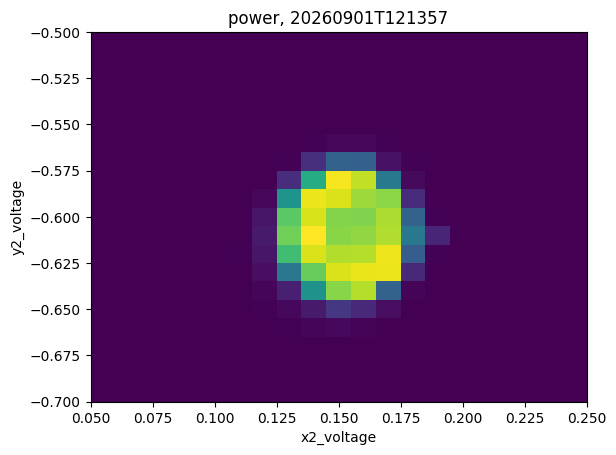

In [18]:
ps.live_plot2D(expt)

In [13]:
# devices.x1.voltage = 0.02
# devices.y1.voltage = -0.02
# devices.x2.voltage = 0.17
# devices.y2.voltage = -0.63
devices.x1.voltage = -.1
devices.y1.voltage = -.1
devices.x2.voltage = 0.17
devices.y2.voltage = -0.63
sleep(1)

In [ ]:
# Create RunInfo instance and set scan0 and scan1 to PropertyScan
runinfo = ps.RunInfo()
runinfo.scan0 = ps.PropertyScan({'x1': ps.drange(-0.1, 0.01, 0.1)}, prop='voltage', dt=0.1)
runinfo.scan1 = ps.PropertyScan({'y1': ps.drange(-0.1, 0.01, 0.1)}, prop='voltage', dt=0.1)

runinfo.measure_function = measure_power

expt = ps.Experiment(runinfo, devices)
expt.start_thread()

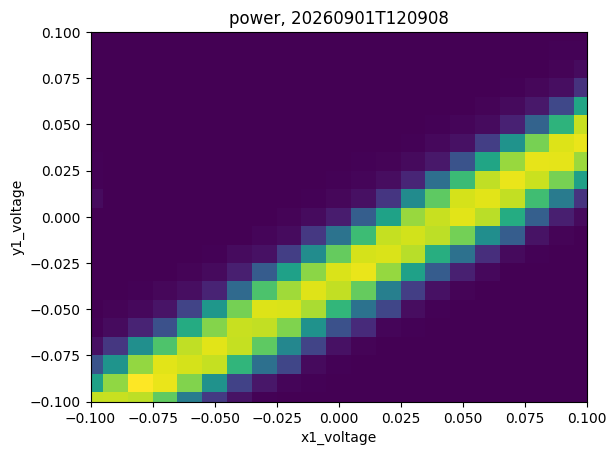

In [15]:
ps.live_plot2D(expt)